# Extrapolation (1-D) and scattered data (2-D) with `scipy.interpolate`

Interpolation evaluates $p$ **between** the data points. **Extrapolation** evaluates it **outside** the data, to the left of $x_0$ or to the right of $x_n$.
There is no data there, so each method simply continues the formula it uses at the end of the data. The result depends only on the method, not on the true function.

This notebook has two parts:

**A. Extrapolation in 1-D** with the five methods from class:

| method | call | extrapolates by default? |
|---|---|---|
| linear | `si.make_interp_spline(x, y, k=1)` | yes, continues the last line |
| linear (NumPy) | `np.interp(xnew, x, y)` | no, holds the end value constant |
| cubic spline | `si.CubicSpline(x, y)` | yes, continues the last cubic |
| PCHIP | `si.PchipInterpolator(x, y)` | yes, continues the last cubic |
| Akima | `si.Akima1DInterpolator(x, y)` | **no**, returns `nan`; use `extrapolate=True` |
| Makima | `si.Akima1DInterpolator(x, y, method="makima")` | **no**, returns `nan`; use `extrapolate=True` |

**B. Scattered data in 2-D** with `griddata` and `RBFInterpolator`. Here the "outside" is everything beyond the triangles between the data points.

- Extrapolation is **never** as reliable as interpolation. A method that is safe inside the data (PCHIP: no overshoot) can still produce nonsense outside it.
- The error grows quickly with the distance from the last data point. Only extrapolate a short distance, and only if you have a reason to trust the trend.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.interpolate as si

## Part A. Extrapolation in 1-D

### Example 1: the running example, extended beyond the data

The seven heights $h = (0, 0.1, 0.3, 1.8, 2.0, 2.0, 2.1)$ at $x = 0, 1, \dots, 6$. We build the five interpolants and evaluate them on $[-2, 8]$, two units beyond the data on each side.
Akima and Makima need `extrapolate=True`, otherwise they return `nan` outside $[0, 6]$.

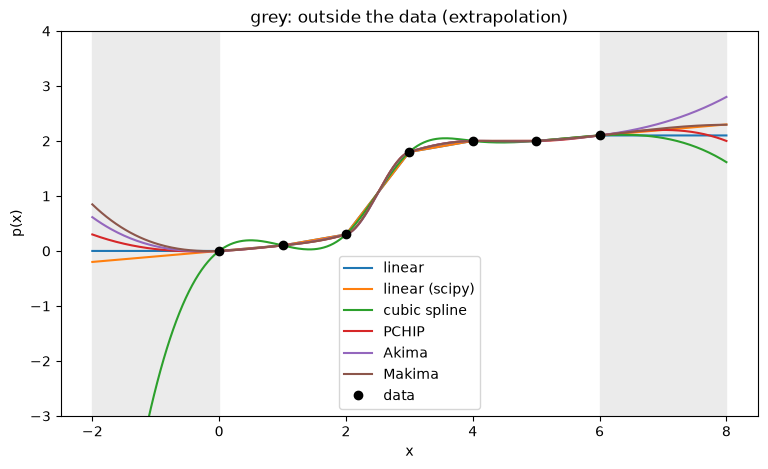

In [2]:
x = np.arange(7.)
h = np.array([0, 0.1, 0.3, 1.8, 2.0, 2.0, 2.1])

names = ["linear", "linear (scipy)", "cubic spline", "PCHIP", "Akima", "Makima"]
methods = [lambda z: np.interp(z, x, h),
           si.make_interp_spline(x, h, k=1),
           si.CubicSpline(x, h),
           si.PchipInterpolator(x, h),
           si.Akima1DInterpolator(x, h, extrapolate=True),
           si.Akima1DInterpolator(x, h, method="makima", extrapolate=True)]

xnew = np.linspace(-2, 8, 401)

fig, ax = plt.subplots(figsize=(9, 5))
ax.axvspan(-2, 0, color="0.92"); ax.axvspan(6, 8, color="0.92")   # extrapolation zones
for name, p in zip(names, methods):
    ax.plot(xnew, p(xnew), label=name)
ax.plot(x, h, "ko", label="data")
ax.set_ylim(-3, 4)
ax.set_xlabel("x"); ax.set_ylabel("p(x)")
ax.set_title("grey: outside the data (extrapolation)")
ax.legend()
plt.show()

The values at a few points outside the data:

In [3]:
xe = np.array([-2, -1, -0.5, 6.5, 7, 8])
print(f"{'x':>14s}" + "".join(f"{v:8.1f}" for v in xe))
for name, p in zip(names, methods):
    print(f"{name:>14s}" + "".join(f"{v:8.3f}" for v in p(xe)))
print(f"{'np.interp':>14s}" + "".join(f"{v:8.3f}" for v in np.interp(xe, x, h)))

             x    -2.0    -1.0    -0.5     6.5     7.0     8.0
        linear   0.000   0.000   0.000   2.100   2.100   2.100
linear (scipy)  -0.200  -0.100  -0.050   2.150   2.200   2.300
  cubic spline  -9.886  -2.496  -0.793   2.110   2.054   1.614
         PCHIP   0.300   0.033  -0.006   2.169   2.200   2.000
         Akima   0.614   0.086   0.004   2.194   2.333   2.800
        Makima   0.847   0.137   0.018   2.167   2.229   2.295
     np.interp   0.000   0.000   0.000   2.100   2.100   2.100


- Inside $[0, 6]$ all methods agree well. Outside they go in **different directions**: at $x = -2$ the values range from about $-9.9$ (cubic spline) to $+0.8$ (Makima).
- **Cubic spline** is the worst: its last cubic has a large curvature, so it shoots off quickly.
- **PCHIP** never overshoots *inside* the data, but outside it just continues a cubic; it is not monotone there either (on the right it rises to 2.2 at $x=7$ and falls back to 2.0 at $x=8$).
- **Linear** continues the last straight line: simple and predictable, but it can still go negative (here $-0.2$ at $x=-2$).
- `np.interp` does not extrapolate at all: it **repeats the end value**.

### Akima and Makima return `nan` by default

In [4]:
print("Akima,  default      :", si.Akima1DInterpolator(x, h)([-1, 7]))
print("Akima,  extrapolate  :", si.Akima1DInterpolator(x, h, extrapolate=True)([-1, 7]))
print("CubicSpline, extrapolate=False:", si.CubicSpline(x, h, extrapolate=False)([-1, 7]))

Akima,  default      : [nan nan]
Akima,  extrapolate  : [0.08571429 2.33333333]
CubicSpline, extrapolate=False: [nan nan]


- `nan` is a **safe** default: you notice immediately that you left the data.
- Every method in the table accepts `extrapolate=True/False` (except `make_interp_spline`, where the option is `extrapolate` when you **evaluate**: `p(xnew, extrapolate=False)`).

### Example 2: how fast does the extrapolation error grow?

Sample $f(x) = \sin x$ at 11 equally spaced points on $[0, \pi]$ and evaluate on $[0, 1.5\pi]$. Inside the data all methods are accurate; we look at what happens beyond $x = \pi$.

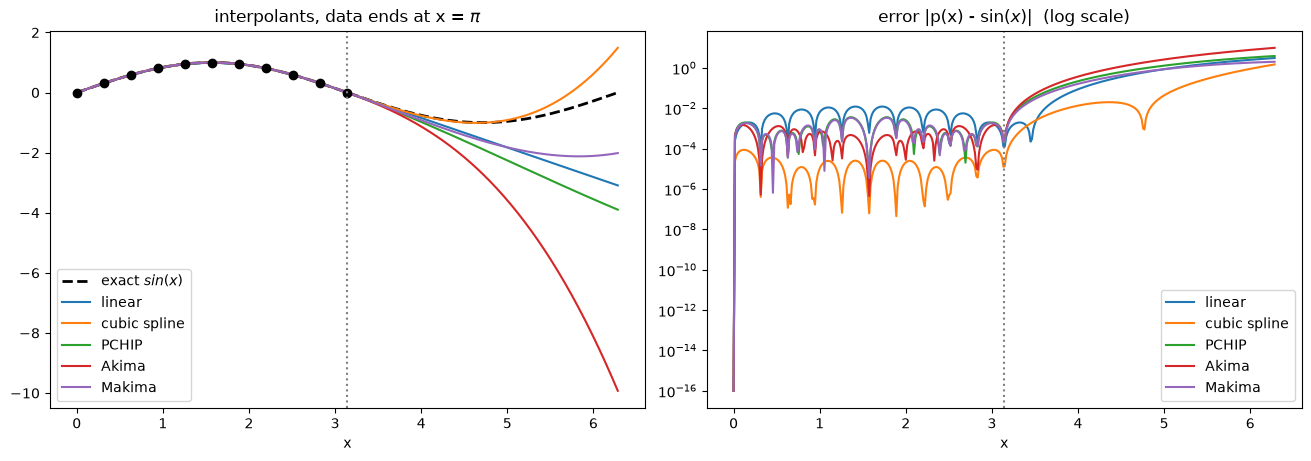

 distance past π        linear  cubic spline         PCHIP         Akima        Makima
             0.1      1.47e-03      2.75e-04      4.77e-03      5.50e-03      4.02e-03
             0.5      1.24e-02      4.71e-03      6.97e-02      1.06e-01      5.39e-02
             1.0      1.42e-01      1.71e-02      3.11e-01      5.43e-01      2.26e-01
             1.5      4.78e-01      1.16e-02      7.92e-01      1.51e+00      5.48e-01


In [5]:
xs = np.linspace(0, np.pi, 11)
ys = np.sin(xs)
names = ["linear",  "cubic spline", "PCHIP", "Akima", "Makima"]
ps = [si.make_interp_spline(xs, ys, k=1),
      si.CubicSpline(xs, ys),
      si.PchipInterpolator(xs, ys),
      si.Akima1DInterpolator(xs, ys, extrapolate=True),
      si.Akima1DInterpolator(xs, ys, method="makima", extrapolate=True)]

xf = np.linspace(0, 2.*np.pi, 400)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
axs[0].plot(xf, np.sin(xf), "k--", lw=2, label=r"exact $sin(x)$")
for name, p in zip(names, ps):
    axs[0].plot(xf, p(xf), label=name)
    axs[1].semilogy(xf, np.abs(p(xf) - np.sin(xf)) + 1e-16, label=name)
axs[0].plot(xs, ys, "ko")
for ax in axs:
    ax.axvline(np.pi, color="0.5", ls=":")
    ax.set_xlabel("x"); ax.legend()
axs[0].set_title(r"interpolants, data ends at x = $\pi$")
axs[1].set_title(r"error |p(x) - $\sin(x)$|  (log scale)")
plt.show()

print(f"{'distance past π':>16s}" + "".join(f"{n:>14s}" for n in names))
for d in [0.1, 0.5, 1.0, 1.5]:
    xp = np.pi + d
    print(f"{d:16.1f}" + "".join(f"{abs(p(xp) - np.sin(xp)):14.2e}" for p in ps))

- Inside $[0, \pi]$ the errors are tiny. Just past $\pi$ they jump up by orders of magnitude for every method.
- Here the **cubic spline** is by far the best extrapolator (error about $0.01$ even at $d = 1.5$): $\sin x$ is smooth, and the spline's last cubic has the right curvature. PCHIP, Akima and Makima flatten their end slopes, so they miss the turn of the sine and are off by $0.5$ to $1.5$ at $d = 1.5$.
- Compare with Example 1, where the cubic spline was the **worst**. Which method extrapolates best depends entirely on the data; there is no safe choice.
- **Rule of thumb:** extrapolate at most a small fraction of the data spacing, and always plot the result.

## Part B. Scattered data in 2-D

Now the data are at 100 **random** points in $[0, 2\pi]^2$, from $f(x, y) = \sin x \cos y$.
There is no grid, so `RegularGridInterpolator` cannot be used. We use `griddata` and `RBFInterpolator`.

| method | call | continuous | local? | overshoot? | outside the data |
|---|---|---|---|---|---|
| linear (on triangles) | `si.griddata(pts, z, (X, Y), method="linear")` | $p$ | yes | never | `nan` |
| cubic (Clough–Tocher) | `si.griddata(pts, z, (X, Y), method="cubic")` | $p$ and first derivatives | yes | can overshoot | `nan` |
| radial basis functions | `si.RBFInterpolator(pts, z)` | smooth | no | can overshoot | extrapolates |

- `si.griddata(pts, z, (Xn, Yn), method=...)` builds **and** evaluates in one call. `pts` has shape `(N, 2)`, one row $(x_k, y_k)$ per point.
- `griddata` splits the plane into **triangles** between the data points. Outside the triangles (the *convex hull* of the points) it returns `nan`, or the value given by `fill_value=...`.
- `si.RBFInterpolator(pts, z)` builds one smooth function from all points; it is evaluated at points of shape `(M, 2)`. To evaluate on a mesh, flatten the mesh into points and reshape the result back. It is defined everywhere, so it **extrapolates** outside the data.

More details: <https://docs.scipy.org/doc/scipy/tutorial/interpolate/ND_unstructured.html>

### Example 3: scattered samples of $\sin x \cos y$

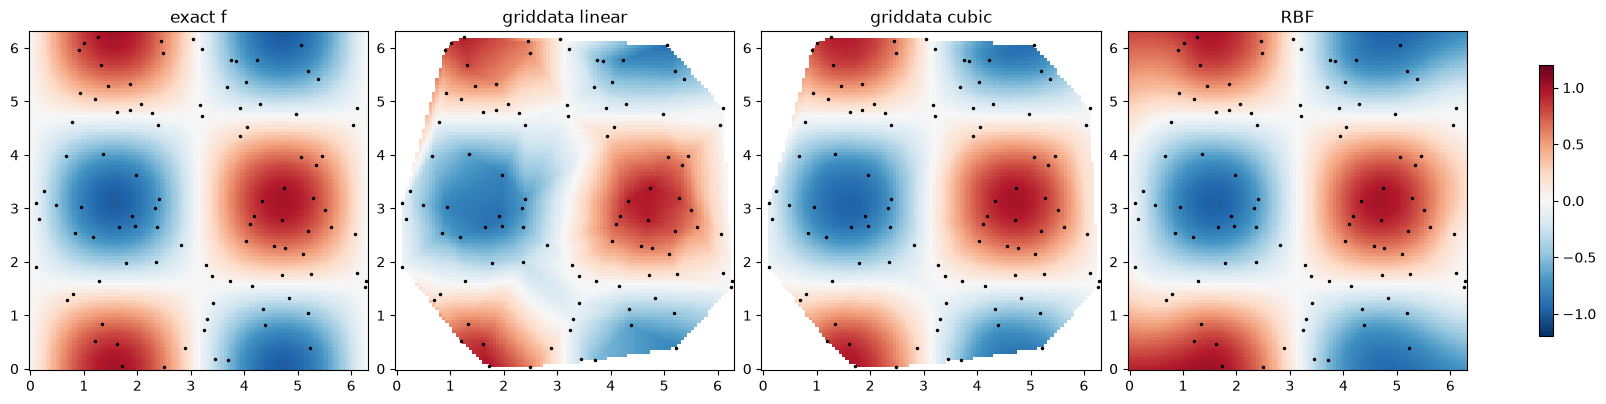

In [6]:
def f(x, y):
    return np.sin(x) * np.cos(y)

rng = np.random.default_rng(1)          # fixed seed: same "random" points every run
pts = rng.uniform(0, 2*np.pi, size=(100, 2))
z = f(pts[:, 0], pts[:, 1])

xnew4 = np.linspace(0, 2*np.pi, 101)
Xn4, Yn4 = np.meshgrid(xnew4, xnew4, indexing="ij")

V_lin = si.griddata(pts, z, (Xn4, Yn4), method="linear")
V_cub = si.griddata(pts, z, (Xn4, Yn4), method="cubic")
rbf = si.RBFInterpolator(pts, z)
V_rbf = rbf(np.column_stack([Xn4.ravel(), Yn4.ravel()])).reshape(Xn4.shape)

fig, axs = plt.subplots(1, 4, figsize=(16, 3.8), constrained_layout=True)
panels = [("exact f", f(Xn4, Yn4)), ("griddata linear", V_lin),
          ("griddata cubic", V_cub), ("RBF", V_rbf)]
for ax, (title, V) in zip(axs, panels):
    im = ax.pcolormesh(Xn4, Yn4, V, shading="auto", cmap="RdBu_r", vmin=-1.2, vmax=1.2)
    ax.plot(pts[:, 0], pts[:, 1], "k.", ms=3)
    ax.set_title(title); ax.set_aspect("equal")
fig.colorbar(im, ax=axs, shrink=0.8)
plt.show()

The white areas in the `griddata` pictures are `nan`: those points lie **outside** the triangles, so `griddata` refuses to answer. RBF fills the whole square.

To compare the methods fairly we measure the error only where `griddata` gives a value. With scattered points the maximum error is dominated by a few long, thin triangles near the edge, so we also print the **root-mean-square (RMS) error**, a typical error over the mesh.

In [7]:
F = f(Xn4, Yn4)
inside = ~np.isnan(V_lin)                     # True where griddata has a value
print(f"points outside the triangles: {100 * (~inside).mean():.1f} %\n")

print(f"{'method':16s} {'max err':>9s} {'RMS err':>9s}   (inside only)")
for name, V in [("griddata linear", V_lin), ("griddata cubic", V_cub), ("RBF", V_rbf)]:
    e = np.abs(V - F)[inside]
    print(f"{name:16s} {e.max():9.3f} {np.sqrt(np.mean(e**2)):9.3f}")

e_out = np.abs(V_rbf - F)[~inside]
print(f"\nRBF outside the triangles: max err = {e_out.max():.3f}")

points outside the triangles: 19.6 %

method             max err   RMS err   (inside only)
griddata linear      0.414     0.078
griddata cubic       0.146     0.017
RBF                  0.168     0.018

RBF outside the triangles: max err = 0.930


- `griddata` gives **no answer** near the corners and edges of the square. Use `fill_value=...` to choose what is returned there instead of `nan`.
- Cubic and RBF are about equally accurate inside, and both are much better than linear (RMS error about 4 times smaller).
- RBF **does** answer outside the data, but there it is extrapolating. Its error there is several times larger than inside: just as in 1-D, be careful trusting values far from any data point.

## Exercises

**Syntax: 1-D methods**, data `x` (increasing) and `y`:

| method | build | evaluate | extrapolate? |
|---|---|---|---|
| linear | `p = si.make_interp_spline(x, y, k=1)` | `p(xnew)` | yes (`p(xnew, extrapolate=False)` gives `nan`) |
| linear, constant ends | (none) | `np.interp(xnew, x, y)` | holds end values |
| cubic spline | `p = si.CubicSpline(x, y)` | `p(xnew)` | yes |
| PCHIP | `p = si.PchipInterpolator(x, y)` | `p(xnew)` | yes |
| Akima | `p = si.Akima1DInterpolator(x, y, extrapolate=True)` | `p(xnew)` | only with `extrapolate=True` |
| Makima | `p = si.Akima1DInterpolator(x, y, method="makima", extrapolate=True)` | `p(xnew)` | only with `extrapolate=True` |

**Syntax: scattered 2-D data**, `pts` of shape `(N, 2)` and `z` of shape `(N,)`:

| method | build | evaluate on a mesh |
|---|---|---|
| linear | (none) | `si.griddata(pts, z, (Xn, Yn), method="linear")` |
| cubic | (none) | `si.griddata(pts, z, (Xn, Yn), method="cubic")` |
| RBF | `r = si.RBFInterpolator(pts, z)` | `r(np.column_stack([Xn.ravel(), Yn.ravel()])).reshape(Xn.shape)` |

<br>

| useful extra | call |
|---|---|
| $n$ equally spaced points on $[a, b]$ | `np.linspace(a, b, n)` |
| a mesh from two vectors | `X, Y = np.meshgrid(x, y, indexing="ij")` |
| evaluate at a few single points (2-D) | `si.griddata(pts, z, [[x1, y1], [x2, y2]])`, `r([[x1, y1], [x2, y2]])` |
| value instead of `nan` outside the data | `si.griddata(..., fill_value=v)` |
| smallest and largest value (ignoring `nan`) | `np.nanmin(V)`, `np.nanmax(V)` |
| maximum error against a known $f$ | `np.max(np.abs(V - f(Xn, Yn)))` (use `np.nanmax` if `V` has `nan`) |
| shade the extrapolation zone in a plot | `ax.axvspan(a, b, color="0.9")` |

<br>

| plotting | call |
|---|---|
| a row of `k` plots | `fig, axs = plt.subplots(1, k, figsize=(4*k, 4), constrained_layout=True)` |
| colour plot of a surface | `im = ax.pcolormesh(Xn, Yn, V, shading="auto")` |
| same colour scale on all plots | `ax.pcolormesh(..., vmin=a, vmax=b)` |
| colour bar | `fig.colorbar(im, ax=axs)` |
| plot the data points | `ax.plot(pts[:, 0], pts[:, 1], "k.")` |
| equal scale on both axes | `ax.set_aspect("equal")` |

**Exercise 1 (1-D interpolation and extrapolation).** A cup of coffee cools in a room. Its temperature in centigrade is measured at these times (minutes):

```python
t = np.array([0, 2, 5, 10, 15, 20, 30.])
T = np.array([90.0, 81.0, 69.4, 51.2, 41.0, 34.8, 26.5])
```

(a) Build the five interpolants (linear, cubic spline, PCHIP, Akima, Makima). Plot them on $[0, 30]$ (use `tn = np.linspace(0,30, 50)`) together with the data. Print the five estimates of the temperature at $t = 7$ and $t = 25$ minutes.

(b) Now **extrapolate**: evaluate all five on $[0, 60]$ (use `tn = np.linspace(0,60, 100)`) and plot them, with the extrapolation zone $[30, 60]$ shaded. Print the five predictions at $t = 35$, $45$ and $60$ minutes.

(c) The cooling follows (approximately) Newton's law, $T(t) = 20 + 70\,e^{-0.08\,t}$. Print the error of each prediction from (b). Which method does best a short distance past the data, and which far from it? Which methods give a physically impossible answer (a temperature below the room temperature of 20 °C, or a coffee that warms up again)?

In [8]:
# Exercise 1
t = np.array([0, 2, 5, 10, 15, 20, 30.])
T = np.array([90.0, 81.0, 69.4, 51.2, 41.0, 34.8, 26.5])




**Exercise 2 (2-D scattered data).** Twelve weather stations in a $100 \times 100$ km region measure the temperature (°C). Station 12 is on a mountain top.

```python
sx = np.array([10, 30, 55, 80, 15, 40, 65, 85, 20, 50, 75, 45.])     # km east
sy = np.array([15, 10, 20, 15, 45, 40, 50, 45, 80, 75, 85, 60.])     # km north
T  = np.array([14.2, 15.1, 13.8, 12.9, 11.5, 9.8, 6.2, 11.8, 10.4, 8.9, 10.1, 3.5])
pts = np.column_stack([sx, sy])
```

(a) Make a temperature map on a mesh of $201 \times 201$ points over $[0, 100]^2$ with `griddata` (linear and cubic) and with `RBFInterpolator`. Plot the three maps with the stations marked.

(b) Print the smallest and largest temperature of each map (`np.nanmin`, `np.nanmax`). The measurements are between 3.5 and 15.1 °C. Which methods go outside this range?

In [9]:
# Exercise 2
sx = np.array([10, 30, 55, 80, 15, 40, 65, 85, 20, 50, 75, 45.])     # km east
sy = np.array([15, 10, 20, 15, 45, 40, 50, 45, 80, 75, 85, 60.])     # km north
T  = np.array([14.2, 15.1, 13.8, 12.9, 11.5, 9.8, 6.2, 11.8, 10.4, 8.9, 10.1, 3.5])
pts = np.column_stack([sx, sy])
